# Aperiodic sample: phase retrieval for one hysteresis state

Run `00_preprocess_2871_2872.ipynb` once. This notebook reads its repository cache and reconstructs saturated scan 2923 and one selected state from scan 2924 using the current unified library. Both scans have the same helicity.


Set the scan numbers in the first settings cell to match notebook 00. The support is loaded from its preprocessing cache.

Detector exclusions now come from the scan-pair painted PNG only, plus automatic saturation exclusions when stored separately in a new cache. JSON polygon coordinates, legacy combined masks, implicit dilation and hard-coded excluded columns are not applied. Re-run 00 to preserve automatic saturation masks when using an older cache.


In [ ]:
from pathlib import Path
import sys, json
import h5py
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "00_preprocess_2871_2872.ipynb").is_file():
    HERE = HERE / "aperiodic_ajajas"
if not (HERE / "00_preprocess_2871_2872.ipynb").is_file():
    raise FileNotFoundError("Run from the repository root or aperiodic_ajajas")
REPO = HERE.parent
sys.path.insert(0, str(REPO))
# Match the scan numbers used in notebook 00.






SATURATED_SCAN = 2923
LOOP_SCAN = 2924
SUPPORT_DILATION = 0
SUPPORT_EROSION = 0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0
DISPLAY_PROP_DX=0
roi=np.s_[225:383,257:410]
SUPPORT_CENTER_RADIUS = 10.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25  # Acquisition point number; overridden by the named profile.





SATURATED_SCAN = 2871
LOOP_SCAN = 2872
SUPPORT_DILATION = 6
SUPPORT_EROSION = 0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0.9
DISPLAY_PROP_DX=0
roi=np.s_[215:373,267:420]
SUPPORT_CENTER_RADIUS = 0.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25  # Acquisition point number; overridden by the named profile.


SATURATED_SCAN = 2871
LOOP_SCAN = 2873
SUPPORT_DILATION = 6
SUPPORT_EROSION = 0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0.9
DISPLAY_PROP_DX=0
roi=np.s_[215:373,267:420]
SUPPORT_CENTER_RADIUS = 0.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25  # Acquisition point number; overridden by the named profile.


SATURATED_SCAN = 2919
LOOP_SCAN = 2920
LOOP_SCAN = 2920
SUPPORT_DILATION = 1
SUPPORT_EROSION = 0
DISPLAY_PROP_DY=0.9
DISPLAY_PROP_DX=0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76+np.pi/4
roi=np.s_[225:385,258:412]
SUPPORT_CENTER_RADIUS = 10.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25


SATURATED_SCAN = 2923
LOOP_SCAN = 2925
SUPPORT_DILATION = 0
SUPPORT_EROSION = 0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0
DISPLAY_PROP_DX=0
roi=np.s_[273:451,309:481]
SUPPORT_CENTER_RADIUS = 10.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25  # Acquisition point number; overridden by the named profile.


SATURATED_SCAN = 2919
LOOP_SCAN = 2920
LOOP_SCAN = 2920
SUPPORT_DILATION = 1
SUPPORT_EROSION = 0
DISPLAY_PROP_DY=0.9
DISPLAY_PROP_DX=0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76+np.pi/4
roi=np.s_[225:385,258:412]   # for crop 500
roi=np.s_[272:455,308:486]   # for crop 400
SUPPORT_CENTER_RADIUS = 10.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25


#SATURATED_SCAN = 2930
#LOOP_SCAN = 2931
#SUPPORT_DILATION = 1
#SUPPORT_EROSION = 0
#DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
#DISPLAY_PHASE_RAD = -0.76
#DISPLAY_PROP_DY=0
#DISPLAY_PROP_DX=0
#roi=np.s_[225:383,257:410]
#SUPPORT_CENTER_RADIUS = 10.0  # Cached-grid pixels; 0 disables the central reference circle.
#STATE_POINT_NUMBER = 0# Acquisition point number; overridden by the named profile.


OUTPUT_DIR = HERE / "processed" / f"scans_{SATURATED_SCAN}_{LOOP_SCAN}"
from aperiodic_ajajas.result_io import prepare_painted_detector_mask, painted_cache_mask
MASK_PIXEL_PNG = HERE / f"mask_pixel_{SATURATED_SCAN}.png"
from library import fthcore as fth
from library.phase_retrieval_geometry import recenter_source_support
from aperiodic_ajajas.reconstruction_inputs import (
    detector_file_point_indices,
    fit_reference_intensity,
)
CACHE = HERE / "processed" / f"preprocessed_{LOOP_SCAN}_{SATURATED_SCAN}.h5"
if not CACHE.is_file():
    raise FileNotFoundError(f"Run 00_preprocess_2871_2872.ipynb first: {CACHE}")




MODES = [1,2]  # Copy2 single-mode baseline; set [1, 2] to test multimode.
MODE_SUPPORT_CENTER = "image"  # Scale the entire support, including aperture separations.
RETRIEVAL_CROP = 400
RETRIEVAL_BINNING = 1
USE_PARTIAL_COHERENCE = False  # Copy2 adds Richardson-Lucy refinement after coherent retrieval.
NORMALIZE_LOOP_INTENSITY = False  # Copy2 active CDI loop fits a factor for FTH, but retrieves unscaled im_c.
HOLOGRAM_OFFSET = 0.0  # Copy2 phase-retrieval offset; fitted correlation intercept is not applied.
SUPPORT_SHIFT = (0, 0)  # Cached support already aligns with scan 2923; (row, column) pixels.
# Support adjustment on the cached object grid, before retrieval crop/binning.
# Erosion first, then dilation; 0 skips the operation.
SUPPORT_PNG = HERE / f"supportmask_{SATURATED_SCAN}.png"




OUTPUT = OUTPUT_DIR / f"two_state_point_{STATE_POINT_NUMBER:04d}.h5"
plt.close("all")


def select_numbers(available, requested=None, step=1, exclude=()):
    """Return positions in available, selecting acquisition numbers, not positions."""
    available = [int(v) for v in available]
    if len(set(available)) != len(available):
        raise ValueError('Duplicate acquisition point numbers')
    if requested is None:
        if type(step) is not int or step < 1:
            raise ValueError('Selection step must be a positive integer')
        result = [i for i, value in enumerate(available) if value not in exclude][::step]
    else:
        if not requested or any(type(v) is not int or v < 0 for v in requested):
            raise ValueError('Selection must be a nonempty list of nonnegative integers')
        if len(set(requested)) != len(requested):
            raise ValueError('Duplicate requested indices')
        missing = set(requested) - set(available)
        if missing:
            raise ValueError(f'Requested indices are unavailable: {sorted(missing)}')
        result = [available.index(v) for v in requested]
    if not result:
        raise ValueError('Selection is empty')
    return result


## Read the prepared repository cache


101 [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100]
Support pixels before/after: 48799 49712
Support shift on cached object grid: (0, 0)
Loaded support PNG: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/supportmask_2919.png ; central circle radius: 10.0
Copy2 intensity fit (diagnostic): loop = 0.958801 × saturated + 0.534032
Applied loop normalization: False input offset: 0.0
Loaded cache: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/preprocessed_2920_2919.h5 shape: (2048, 2048) scan point: 25 loop current: 0.502125024796 A


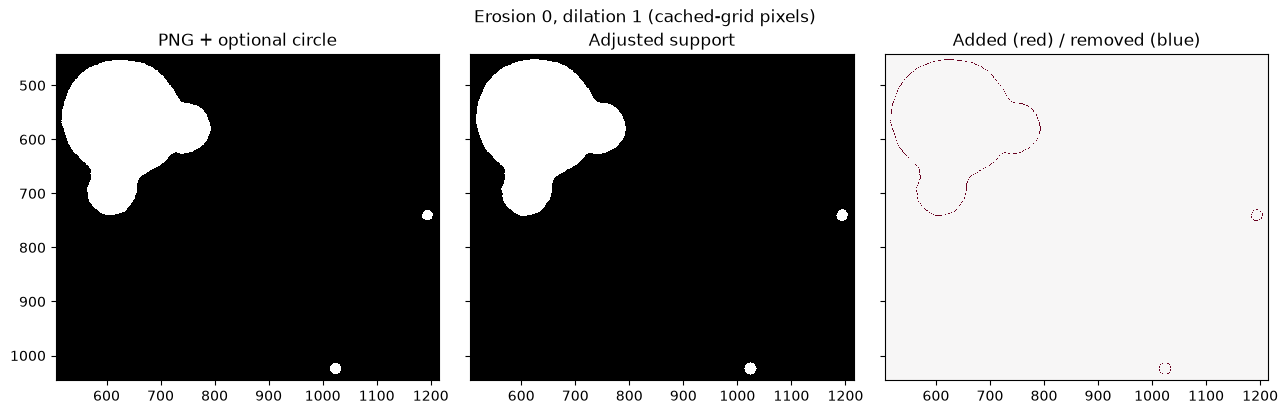

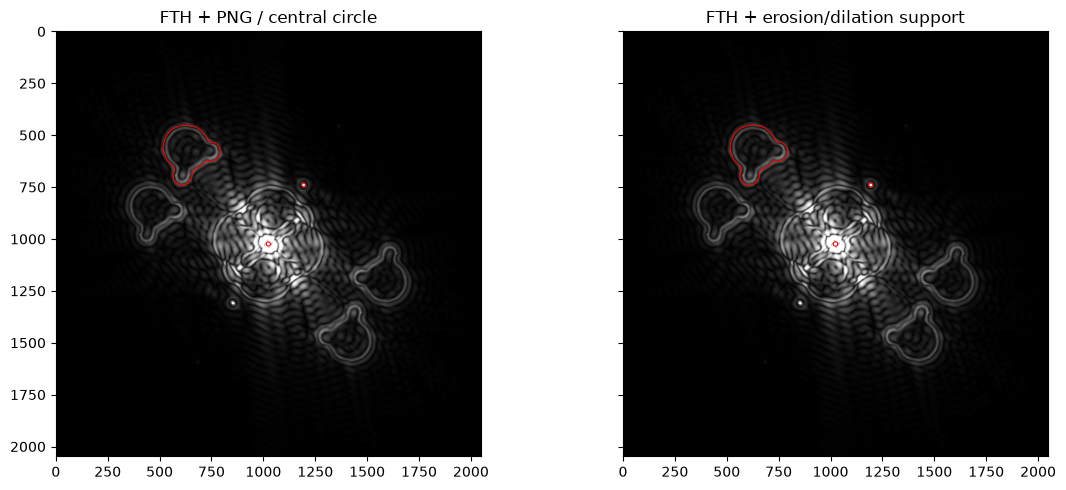

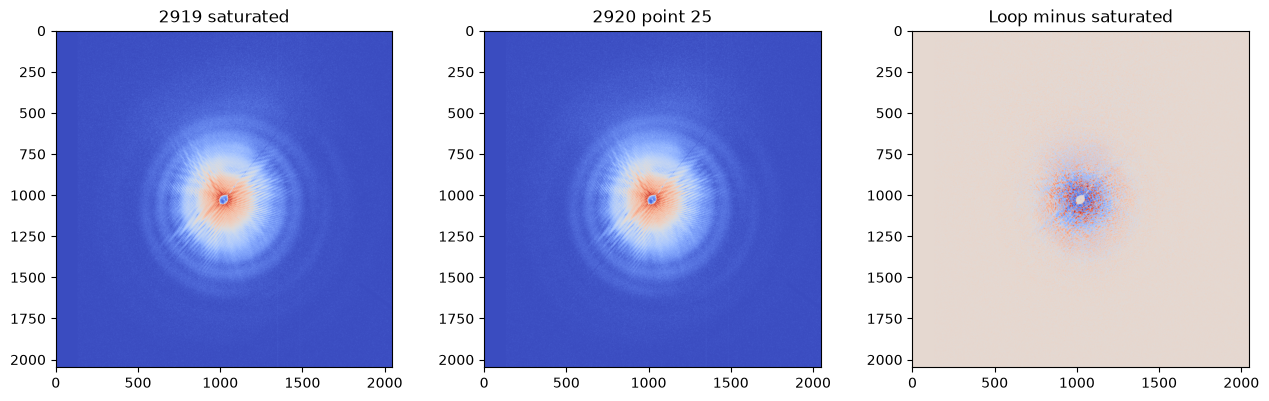

In [2]:
with h5py.File(CACHE) as h:
    cache_config = json.loads(h.attrs["config_json"])
    if (cache_config.get("saturated_scan") != SATURATED_SCAN
            or cache_config.get("loop_scan") != LOOP_SCAN):
        raise ValueError("Cache scan numbers do not match notebook settings")
    if (cache_config.get("crop_raw_pixels") != 0
            or cache_config.get("binning") != 1
):
        raise ValueError("Cached preprocessing uses the old geometry or pixel mask. Re-run 00_preprocess_2871_2872.ipynb.")
    ENERGY_EV = float(h.attrs["photon_energy_eV"])
    n_states = h["loop_holograms"].shape[0]
    loop_point_indices = detector_file_point_indices(h["loop_file_names"].asstr()[:])
    print(n_states,loop_point_indices)
    if len(loop_point_indices) != n_states:
        raise ValueError("Loop file list and hologram stack have different lengths")
    STATE_INDEX = select_numbers(loop_point_indices, [STATE_POINT_NUMBER])[0]
    if not 0 <= STATE_INDEX < n_states:
        raise IndexError(f"STATE_INDEX must be between 0 and {n_states-1}")
    reference = h["saturated_hologram"][()]
    painted_detector_mask = prepare_painted_detector_mask(reference, MASK_PIXEL_PNG)
    reference_mask = painted_cache_mask(h, None, painted_detector_mask)
    loop_image = h["loop_holograms"][STATE_INDEX]
    loop_mask = painted_cache_mask(h, STATE_INDEX, painted_detector_mask)
    loop_current = h["loop_current_A"][()]
# Load the painted PNG here, independently of the preprocessing cache.
from PIL import Image
from scipy.ndimage import zoom, binary_erosion, binary_dilation
painted_rgb = np.asarray(Image.open(SUPPORT_PNG).convert("RGB"))
painted_support = np.all(painted_rgb == (255, 0, 0), axis=-1)
if not painted_support.any():
    raise ValueError(f"No pure-red support pixels in {SUPPORT_PNG}")
support_png_grid = zoom(painted_support.astype(float),
                       np.asarray(reference.shape) / np.asarray(painted_support.shape), order=3) > 0.5
support_used = np.roll(support_png_grid, shift=SUPPORT_SHIFT, axis=(0, 1))
if not np.isfinite(SUPPORT_CENTER_RADIUS) or SUPPORT_CENTER_RADIUS < 0:
    raise ValueError("SUPPORT_CENTER_RADIUS must be finite and nonnegative")
if SUPPORT_CENTER_RADIUS > 0:
    yy, xx = np.ogrid[:reference.shape[0], :reference.shape[1]]
    cy, cx = np.asarray(reference.shape) // 2
    support_used |= (yy - cy)**2 + (xx - cx)**2 <= SUPPORT_CENTER_RADIUS**2
for name, iterations in (("SUPPORT_EROSION", SUPPORT_EROSION),
                         ("SUPPORT_DILATION", SUPPORT_DILATION)):
    if type(iterations) is not int or iterations < 0:
        raise ValueError(f"{name} must be a nonnegative integer")
support_before_adjustment = support_used.astype(bool).copy()
support_after_adjustment = support_before_adjustment.copy()
if SUPPORT_EROSION > 0:
    support_after_adjustment = binary_erosion(support_after_adjustment, iterations=SUPPORT_EROSION)
if SUPPORT_DILATION > 0:
    support_after_adjustment = binary_dilation(support_after_adjustment, iterations=SUPPORT_DILATION)
if not support_after_adjustment.any():
    raise ValueError("Adjusted support is empty; reduce SUPPORT_EROSION")
support_adjustment = dict(erosion=SUPPORT_EROSION, dilation=SUPPORT_DILATION,
                          order="circle_then_erosion_then_dilation", grid="cached_object_pixels",
                          center_radius=float(SUPPORT_CENTER_RADIUS), support_png=str(SUPPORT_PNG))
support_used = support_after_adjustment.astype(np.uint8)
fig_support_adjustment, support_axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, values, title in zip(support_axes,
        (support_before_adjustment, support_after_adjustment,
         support_after_adjustment.astype(int) - support_before_adjustment.astype(int)),
        ("PNG + optional circle", "Adjusted support", "Added (red) / removed (blue)")):
    ax.imshow(values, cmap="RdBu_r" if ax is support_axes[2] else "gray",
              vmin=-1 if ax is support_axes[2] else 0, vmax=1, interpolation="nearest")
    ax.set_title(title)
rows, cols = np.nonzero(support_before_adjustment | support_after_adjustment)
for ax in support_axes:
    ax.set_xlim(max(0, cols.min() - 10), min(support_used.shape[1], cols.max() + 11))
    ax.set_ylim(min(support_used.shape[0], rows.max() + 11), max(0, rows.min() - 10))
fig_support_adjustment.suptitle(f"Erosion {SUPPORT_EROSION}, dilation {SUPPORT_DILATION} (cached-grid pixels)")
fig_support_adjustment.tight_layout()
print("Support pixels before/after:", int(support_before_adjustment.sum()), int(support_after_adjustment.sum()))
support_used, support_source_shift = recenter_source_support(
    support_used, RETRIEVAL_CROP, RETRIEVAL_BINNING,
)
print("Support shift on cached object grid:", support_source_shift)
# Check alignment against the actual FTH reconstruction before automatic support recentering.
fth_support_view = np.log1p(np.abs(fth.reconstruct(reference)))
fig_support_fth, axes_support_fth = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
fth_low, fth_high = np.percentile(fth_support_view, [1, 99.8])
for ax, mask, title in zip(axes_support_fth,
        (support_before_adjustment, support_after_adjustment),
        ("FTH + PNG / central circle", "FTH + erosion/dilation support")):
    ax.imshow(fth_support_view, cmap="gray", vmin=fth_low, vmax=fth_high)
    ax.contour(mask, levels=[0.5], colors="red", linewidths=0.7)
    ax.set_title(title)
fig_support_fth.tight_layout()
print("Loaded support PNG:", SUPPORT_PNG, "; central circle radius:", SUPPORT_CENTER_RADIUS)

mask_pixel = (reference_mask | loop_mask).astype(np.uint8)
intensity_factor, fitted_offset = fit_reference_intensity(
    loop_image, reference, mask_pixel,
)
loop_for_retrieval = loop_image / intensity_factor if NORMALIZE_LOOP_INTENSITY else loop_image
holograms = {
    "saturated": reference + HOLOGRAM_OFFSET,
    "loop": loop_for_retrieval + HOLOGRAM_OFFSET,
}
#mask_pixel |= (holograms["saturated"] <= 0) | (holograms["loop"] <= 0)
print(f"Copy2 intensity fit (diagnostic): loop = {intensity_factor:.6g} × saturated + {fitted_offset:.6g}")
print("Applied loop normalization:", NORMALIZE_LOOP_INTENSITY, "input offset:", HOLOGRAM_OFFSET)
print("Loaded cache:", CACHE, "shape:", reference.shape,
      "scan point:", loop_point_indices[STATE_INDEX],
      "loop current:", loop_current[STATE_INDEX], "A")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, im, title in zip(axes, [reference, loop_image, loop_image-reference],
                         [f"{SATURATED_SCAN} saturated", f"{LOOP_SCAN} point {loop_point_indices[STATE_INDEX]}", "Loop minus saturated"]):
    ax.imshow(np.sign(im)*np.log1p(np.abs(im)), cmap="coolwarm")
    ax.set_title(title)#; ax.axis("off")
plt.tight_layout()


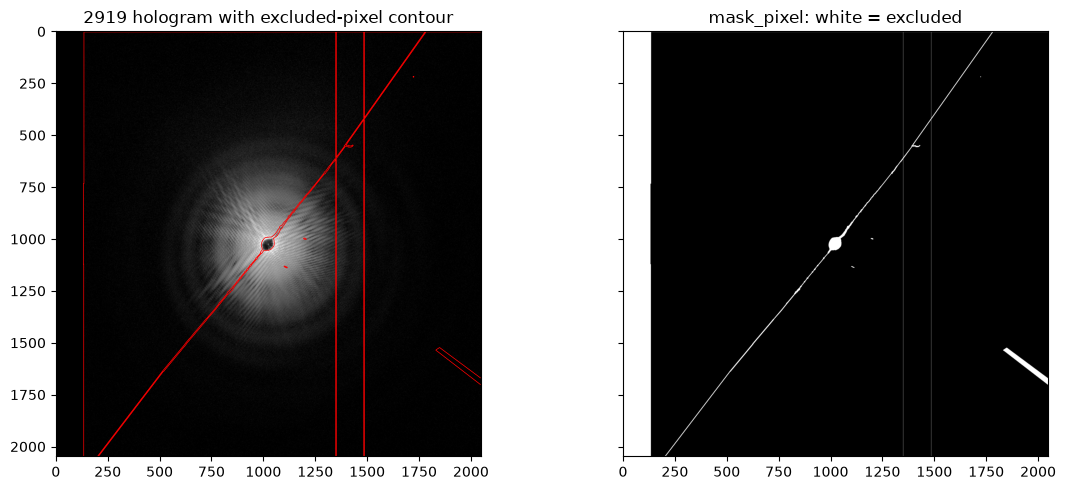

In [3]:
# Inspect the actual detector pixels excluded before phase retrieval.
qa_mask = mask_pixel[0] if mask_pixel.ndim == 3 else mask_pixel
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].imshow(np.log1p(np.maximum(reference, 0)), cmap="gray")
axes[0].contour(qa_mask, levels=[0.5], colors="red", linewidths=0.5)
axes[0].set_title(f"{SATURATED_SCAN} hologram with excluded-pixel contour")
axes[1].imshow(qa_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("mask_pixel: white = excluded")
plt.tight_layout()


## Run the current two-observation phase retrieval

In [4]:
from library import phase_retrieval_core_unified as pr
from library.retrieval_progress import retrieval_progress
recipe = pr.default_phase_retrieval_recipe()
# Reconstruct the saturated reference with HAPRE+ER, then start the loop
# state from that result for a short ER update.
recipe.update(
    algorithm_list=(["HAPRE", "ER", "ER", "HAPRE", "ER", "ER"]
                    if USE_PARTIAL_COHERENCE else ["HAPRE", "ER", "ER"]),
    number_iterations=([700, 50, 50, 700, 50, 50]
                       if USE_PARTIAL_COHERENCE else [700, 50, 50]),
    #helicity=(["loop", "loop", "saturated", "loop", "loop", "saturated"]
    #          if USE_PARTIAL_COHERENCE else ["loop", "loop", "saturated"]),
    helicity=(["saturated", "saturated", "loop", "saturated", "saturated", "loop"]
              if USE_PARTIAL_COHERENCE else ["saturated", "saturated", "loop"]),
    beta_zero=[0.5] * (6 if USE_PARTIAL_COHERENCE else 3),
    beta_mode=(["arctan", "const", "const", "arctan", "const", "const"]
               if USE_PARTIAL_COHERENCE else ["arctan", "const", "const"]),
    alpha_zero=[0.5] * (6 if USE_PARTIAL_COHERENCE else 3),
    alpha_mode=["const"] * (6 if USE_PARTIAL_COHERENCE else 3),
    RL_its=([0]*3 + [50]*3) if USE_PARTIAL_COHERENCE else [0]*3,
    RL_freqs=([1e9]*3 + [20]*3) if USE_PARTIAL_COHERENCE else [1e9]*3,
    TV_freqs=[10] * (6 if USE_PARTIAL_COHERENCE else 3),
    plot_every=[1e9] * (6 if USE_PARTIAL_COHERENCE else 3),
    average_img=[3] * (6 if USE_PARTIAL_COHERENCE else 3),
    Fourier_last=[True] * (6 if USE_PARTIAL_COHERENCE else 3),
    #Startimage=([None, "loop", "loop", "loop", "loop", "loop"]
    #            if USE_PARTIAL_COHERENCE else [None, "loop", "loop"]),
    #Startgamma=([None]*3 + [None, "loop", "loop"]
    Startimage=([None, "saturated", "saturated", "saturated", "saturated", "saturated"]
                if USE_PARTIAL_COHERENCE else [None, "saturated", "saturated"]),
    Startgamma=([None]*3 + [None, "saturated", "saturated"]
                if USE_PARTIAL_COHERENCE else [None]*3),
    output=([False, False, False, False, True, True]
            if USE_PARTIAL_COHERENCE else [False, True, True]),
    hologram_intensity_cutoff_vmin=-1,
    normalize_startimage_between_holograms=True,
    crop=RETRIEVAL_CROP, binning=RETRIEVAL_BINNING, roi=None,
    return_format="dict", modes=MODES, recenter_modal_supports=True,
    mode_support_center=MODE_SUPPORT_CENTER,
)

In [5]:
with retrieval_progress(recipe, kind="unified"):
    result = pr.phase_retrieval_algorithm(holograms, mask_pixel, support_used, recipe)

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

## Compare the reconstructed object fields and save

In [12]:
plt.close("all")

%matplotlib qt

fields = result["full_coherence" if USE_PARTIAL_COHERENCE else "full_coherence"]
print({key: np.asarray(value).shape for key, value in fields.items()})
print("Modal support shifts on retrieval grid:", result["mode_support_shifts"])



DISPLAY_SETUP = {"ccd_dist": 0.125, "px_size": 11e-6, "energy": ENERGY_EV}
def display_object(field):
    primary = field[0] if field.ndim == 3 else field
    temp=(fth.reconstructCDI(fth.propagate(
        primary, DISPLAY_PROP_UM * 1e-6, experimental_setup=DISPLAY_SETUP,
    )) * np.exp(1j * DISPLAY_PHASE_RAD))
    temp=fth.sub_pixel_centering(temp, DISPLAY_PROP_DX, DISPLAY_PROP_DY)
    return temp

objects = {key: display_object(field) for key, field in fields.items()}
difference = objects["loop"] - objects["saturated"]
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for col, (im, title) in enumerate(zip(
    [objects["saturated"], objects["loop"], difference],
    ["Saturated", "Loop", "Loop minus saturated"],
)):
    for row, (component, label) in enumerate([(np.abs, "abs"),(np.real, "real"), (np.imag, "imag")]):
        ax = axes[row, col]
        view = component(im)
        #360:560, 360:560]
        #roi=np.s_[220:536,250:630]
        #roi=np.s_[:150, :150]
        low, high = np.percentile(view[roi], [0.1, 99.9])
        ax.imshow(view[roi], vmin=low, vmax=high, cmap="gray")
        ax.contour(result["supportmask"][0][roi] if result["supportmask"].ndim == 3
                   else result["supportmask"][roi], levels=[0.5], colors="cyan", linewidths=.5)
        ax.set_title(f"{title} ({label})")
        #ax.set_xlim(250, 600)
        #ax.set_ylim(250, 600)
plt.tight_layout()

{'saturated': (2, 1248, 1248), 'loop': (2, 1248, 1248)}
Modal support shifts on retrieval grid: [(0, 0), (76, 0)]


In [7]:
fields = result["partial_coherence" if USE_PARTIAL_COHERENCE else "full_coherence"]
print({key: np.asarray(value).shape for key, value in fields.items()})
print("Modal support shifts on retrieval grid:", result["mode_support_shifts"])




objects = {key: display_object(field) for key, field in fields.items()}
difference = objects["loop"] - objects["saturated"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, (im, title) in enumerate(zip(
    [objects["saturated"], objects["loop"], difference],
    ["Saturated", "Loop", "Loop minus saturated"],
)):
    for row, (component, label) in enumerate([(np.real, "real"), (np.imag, "imag")]):
        ax = axes[row, col]
        view = component(im)
        #roi=np.s_[300:500, 300:500]
        #roi=np.s_[:150, :150]
        
        #roi=np.s_[150:300,150:300]
        low, high = np.percentile(view[roi], [0.1, 99.9])
        ax.imshow(view[roi], vmin=low, vmax=high, cmap="gray")
        ax.contour(result["supportmask"][0][roi] if result["supportmask"].ndim == 3
                   else result["supportmask"][roi], levels=[0.5], colors="cyan", linewidths=.5)
        ax.set_title(f"{title} ({label})")
        #ax.set_xlim(250, 600)
        #ax.set_ylim(250, 600)
plt.tight_layout()


{'saturated': (2, 1248, 1248), 'loop': (2, 1248, 1248)}
Modal support shifts on retrieval grid: [(0, 0), (76, 0)]


In [8]:
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
with h5py.File(OUTPUT, "w") as h:
    h.attrs["support_png"] = str(SUPPORT_PNG)
    h.attrs["support_center_radius"] = float(SUPPORT_CENTER_RADIUS)
    h.attrs["support_adjustment_json"] = json.dumps(support_adjustment)
    h.create_dataset("support_before_adjustment", data=support_before_adjustment, compression="gzip")
    h.create_dataset("support_after_adjustment", data=support_after_adjustment, compression="gzip")
    h.attrs["preprocess_config_json"] = json.dumps(cache_config)
    h.attrs["source_cache"] = str(CACHE)
    h.attrs["support_source_shift"] = support_source_shift
    h.attrs["mode_support_shifts"] = result["mode_support_shifts"]
    h.attrs["workflow"] = "aperiodic_two_state_unified"
    h.attrs["recipe_json"] = json.dumps(recipe, default=str)
    h.attrs["photon_energy_eV"] = ENERGY_EV
    h.attrs["loop_index"] = STATE_INDEX  # Position in the downloaded cache.
    h.attrs["loop_point_index"] = int(loop_point_indices[STATE_INDEX])
    h.attrs["intensity_factor"] = float(intensity_factor)
    h.attrs["fitted_intensity_offset"] = float(fitted_offset)
    h.attrs["hologram_offset"] = float(HOLOGRAM_OFFSET)
    h.attrs["magnet_current_A"] = float(loop_current[STATE_INDEX])
    for name, value in {"field_saturated":fields["saturated"], "field_loop":fields["loop"],
                        "object_difference":difference, "supportmask":result["supportmask"],
                        "mask_pixel":result["mask_pixel"]}.items():
        h.create_dataset(name, data=value, compression="gzip")
print("Saved", OUTPUT)
# Save image-only PNGs of the final displayed reconstruction for every mode.
FINAL_PNG_OUTPUT = OUTPUT.with_suffix("") / "reconstructions_png"
FINAL_PNG_OUTPUT.mkdir(parents=True, exist_ok=True)
fig_support_fth.savefig(FINAL_PNG_OUTPUT / "support_fth_overlay.png", dpi=150)
fig_support_adjustment.savefig(FINAL_PNG_OUTPUT / "support_adjustment.png", dpi=150)
(FINAL_PNG_OUTPUT / "support_adjustment.json").write_text(json.dumps(support_adjustment, indent=2))
for state_name, state_field in fields.items():
    state_modes = state_field[None] if state_field.ndim == 2 else state_field
    for mode_index, mode_field in enumerate(state_modes):
        final_object = display_object(mode_field)
        for component_name, component, cmap in (
            ("amplitude", np.abs, "gray"), ("phase", np.angle, "twilight"),
            ("real", np.real, "gray"), ("imaginary", np.imag, "gray"),
        ):
            values = component(final_object)
            low, high = ((-np.pi, np.pi) if component_name == "phase"
                         else np.percentile(values, [0.1, 99.9]))
            plt.imsave(
                FINAL_PNG_OUTPUT / f"final_{state_name}_mode_{mode_index:02d}_{component_name}.png",
                values, cmap=cmap, vmin=low, vmax=high, origin="upper",
            )
for component_name, component in (("real", np.real), ("imaginary", np.imag)):
    values = component(difference)
    limit = max(float(np.percentile(np.abs(values), 99.9)), 1e-12)
    plt.imsave(FINAL_PNG_OUTPUT / f"final_loop_minus_saturated_{component_name}.png",
               values, cmap="gray", vmin=-limit, vmax=limit, origin="upper")
print("Final reconstruction PNGs:", FINAL_PNG_OUTPUT)


Saved /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/scans_2919_2920/two_state_point_0025.h5
Final reconstruction PNGs: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/scans_2919_2920/two_state_point_0025/reconstructions_png


In [9]:
plt.close("all")